
Model Accuracy: 0.9897094982242054

Classification Report:
               precision    recall  f1-score   support

           0       0.99      0.99      0.99      5814
           1       0.99      0.99      0.99      5167

    accuracy                           0.99     10981
   macro avg       0.99      0.99      0.99     10981
weighted avg       0.99      0.99      0.99     10981



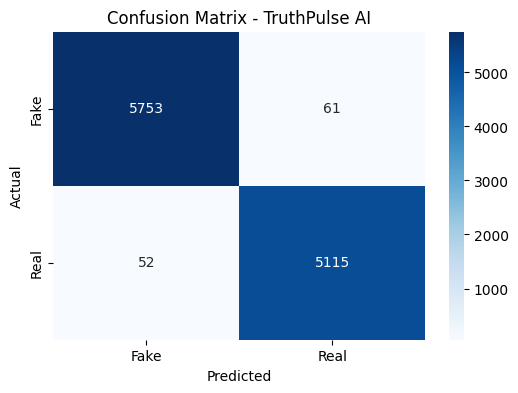

In [1]:
# 📰 Fake News + Fake Facts Detection with GUI

import pandas as pd
import numpy as np
import string
import re
import matplotlib.pyplot as plt
import seaborn as sns
from tkinter import Tk, Text, Button, Label, END

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

# ------------------ 1. Load and Label Data ------------------
# News datasets
true_news_df = pd.read_csv("True.csv")
fake_news_df = pd.read_csv("Fake.csv")

true_news_df['label'] = 1   # Real news
fake_news_df['label'] = 0   # Fake news

# Facts datasets
fake_facts_df = pd.read_csv("final_fake_facts_dataset.csv")
real_facts_df = pd.read_csv("enhanced_real_facts.csv")

fake_facts_df['label'] = 0  # Fake facts
real_facts_df['label'] = 1  # Real facts

# Ensure text column is consistent for facts
if 'text' not in fake_facts_df.columns:
    fake_facts_df['text'] = fake_facts_df.iloc[:, 0].astype(str)
if 'text' not in real_facts_df.columns:
    real_facts_df['text'] = real_facts_df.iloc[:, 0].astype(str)

# Combine all datasets
df = pd.concat([
    pd.DataFrame({'text': true_news_df['title'] + " " + true_news_df['text'], 'label': true_news_df['label']}),
    pd.DataFrame({'text': fake_news_df['title'] + " " + fake_news_df['text'], 'label': fake_news_df['label']}),
    pd.DataFrame({'text': fake_facts_df['text'], 'label': fake_facts_df['label']}),
    pd.DataFrame({'text': real_facts_df['text'], 'label': real_facts_df['label']})
], axis=0).reset_index(drop=True)

# ------------------ 2. Text Cleaning ------------------
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'\[.*?\]', '', text)
    text = re.sub(r'[%s]' % re.escape(string.punctuation), '', text)
    text = re.sub(r'\w*\d\w*', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df['text'] = df['text'].apply(clean_text)

# ------------------ 3. Train/Test Split ------------------
X_train, X_test, y_train, y_test = train_test_split(df['text'], df['label'], test_size=0.2, random_state=42)

# ------------------ 4. TF-IDF Vectorization ------------------
vectorizer = TfidfVectorizer(stop_words='english', max_df=0.7)
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

# ------------------ 5. Model Training ------------------
model = LogisticRegression(max_iter=300)
model.fit(X_train_tfidf, y_train)

# ------------------ 6. Evaluation ------------------
y_pred = model.predict(X_test_tfidf)

print("\nModel Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

# Confusion Matrix Plot
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=["Fake", "Real"],
            yticklabels=["Fake", "Real"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - TruthPulse AI")
plt.show()

# ------------------ 7. Prediction Function ------------------
def predict_text(text):
    cleaned = clean_text(text)
    vectorized = vectorizer.transform([cleaned])
    prediction = model.predict(vectorized)[0]
    return "Real ✅" if prediction == 1 else "Fake ❌"

# ------------------ 8. GUI Application ------------------
def run_gui():
    def classify():
        user_input = text_box.get("1.0", END).strip()
        if user_input:
            result = predict_text(user_input)
            result_label.config(text=f"Prediction: {result}", fg="green" if "Real" in result else "red")
        else:
            result_label.config(text="Please enter text!", fg="orange")

    window = Tk()
    window.title("TruthPulse AI")
    window.geometry("500x400")
    window.resizable(False, False)

    Label(window, text="TruthPulse AI", font=("Arial", 16, "bold")).pack(pady=10)

    Label(window, text="Enter News or Fact:", font=("Arial", 12)).pack()
    text_box = Text(window, height=10, width=55, wrap="word")
    text_box.pack(pady=10)

    Button(window, text="Check", font=("Arial", 12), command=classify).pack(pady=5)

    result_label = Label(window, text="", font=("Arial", 14, "bold"))
    result_label.pack(pady=10)

    window.mainloop()

# ------------------ 9. Run the GUI ------------------
run_gui()
